# Bài tập lý thuyết

Nhóm lập trình xây một bộ phát hiện bài nộp có lỗi. Báo cáo nói “phát hiện được 90% bài lỗi”; vậy một bài bị cảnh báo có xác suất lỗi 90% không? Một thành viên khác thấy gradient âm, sửa trọng số theo, nhưng loss lại tăng. Code vẫn chạy, nên chỉ nhìn màn hình chưa trả lời được hai câu hỏi ấy.

Một lời giải lý thuyết tốt làm lộ những giả thiết mà code có thể che đi. Ta sẽ dùng các ví dụ nhỏ, có lời giải ngay trong bài, để nối xác suất, đại số tuyến tính, tối ưu, kiến trúc mạng và đánh giá. Mục tiêu không phải thuộc thật nhiều công thức, mà là **viết được vì sao phép tính trả lời đúng câu hỏi**. Mỗi mục có một ví dụ tính tay và một đoạn code ngắn để đối chiếu.

> **Mục tiêu sau bài này**
>
> - Trình bày giả thiết, ký hiệu, phép tính và kết luận theo một mạch rõ ràng.
> - Tính Bayes, kỳ vọng, log-loss và đọc mối liên hệ với confusion matrix.
> - Kiểm shape của phép nhân ma trận, tính một bước gradient bằng chain rule và đối chiếu bằng sai phân.
> - Tính kích thước, số tham số của convolution và một hàng attention; giải thích giới hạn của điểm validation.

## Một lời giải cần cho người đọc kiểm được

Trong CP, chứng minh thuật toán thường có invariant và độ phức tạp. Với AI, lời giải cũng cần một đường kiểm tra: đề cho gì, mô hình giả định gì, dùng định nghĩa nào và kết quả có ý nghĩa gì. Chẳng hạn “$p=0.9$” chưa đủ; phải nói đây là $P(\text{cảnh báo}\mid\text{có lỗi})$ hay $P(\text{có lỗi}\mid\text{cảnh báo})$.

Ta dùng quy trình bốn bước. Đầu tiên xác định đại lượng cần trả lời, không tính ngay số dễ có nhất. Sau đó viết ký hiệu cùng domain, shape hoặc đơn vị. Tiếp theo biến đổi công thức trước khi thế số, để người đọc nhận ra phép tính dùng định nghĩa nào. Cuối cùng kiểm bằng một trường hợp nhỏ hoặc code độc lập và diễn giải kết quả. Code là công cụ đối chiếu; dòng `True` không thay thế lời giải thích vì sao.

Hai chiều của việc kiểm không cân nhau. Một khẳng định “với mọi $\mathbf w$” không được chứng minh bằng hữu hạn lần chạy, dù nhiều đến đâu. Ngược lại, một phản ví dụ nhỏ, chạy đúng, đủ để bác bỏ nó.

**Hỏi nhanh.** Đề yêu cầu chứng minh MSE $\frac1n\sum_i(\hat y_i - y_i)^2$ không âm với mọi $\mathbf w$. Một bạn chạy 1000 bộ $\mathbf w$ ngẫu nhiên và thấy loss luôn từ 0 trở lên. Phần này có giá trị gì?

- A. Đủ là một chứng minh, vì 1000 bộ đã là rất nhiều
- B. Chỉ là kiểm tra, vẫn cần lập luận rằng bình phương không âm
- C. Vô ích, vì bài viết không chấm phần chạy code
- D. Đủ, nếu các bộ $\mathbf w$ phủ cả số âm lẫn số dương

<details><summary>Đáp án</summary>

B. Chỉ là kiểm tra, vẫn cần lập luận rằng bình phương không âm

Mỗi số hạng là một bình phương nên không âm, và trung bình các số không âm cũng không âm. Một dòng lập luận là xong. 1000 bộ, kể cả khi phủ đủ hai dấu, vẫn chỉ là hữu hạn trường hợp. Phần chạy vẫn có ích: nếu nó in ra một loss âm thì cài đặt có lỗi.

</details>

## Xác suất: điều kiện nằm ở phía nào?

Giả sử một tập kiểm có đúng 1000 bài nộp: 20 bài có lỗi và 980 bài không lỗi. Detector cảnh báo 18 trong 20 bài lỗi, đồng thời cảnh báo nhầm 98 trong 980 bài sạch.



Chọn ngẫu nhiên đều một bài trong tập này. Gọi $B$ là biến cố “bài có lỗi”, $F$ là “bị cảnh báo”. Ta có $P(B)=20/1000=0.02$, $P(F\mid B)=18/20=0.9$ và $P(F\mid\neg B)=98/980=0.1$. Bayes đảo chiều điều kiện:

$$P(B\mid F)=\frac{P(F\mid B)P(B)}{P(F)}.$$

Mẫu số dùng total probability:

$$P(F)=P(F\mid B)P(B)+P(F\mid\neg B)P(\neg B)=0.018+0.098=0.116.$$

Vậy $P(B\mid F)=0.018/0.116=18/116\approx0.1552$, chỉ khoảng 15.5%. Khi lỗi hiếm, một tỉ lệ báo nhầm nhỏ trên nhóm sạch lớn vẫn sinh nhiều cảnh báo hơn nhóm lỗi. Không có mâu thuẫn với recall 90%; hai câu hỏi dùng hai tập làm mẫu số khác nhau. Recall và tỉ lệ báo nhầm là tính chất của detector; $P(B\mid F)$ còn phụ thuộc tỉ lệ lỗi $P(B)$ của nơi đem detector ra dùng. Bộ phân loại Bayes chọn lớp có xác suất hậu nghiệm lớn nhất; không có đặc trưng nào thì chỉ còn tiền nghiệm, nên với hai lớp chiếm 2/3 và 1/3 ta đoán lớp đông.

In [ ]:
import numpy as np

tp, fn, fp, tn = 18, 2, 98, 882
total = tp + fn + fp + tn
prior = (tp + fn) / total
sensitivity = tp / (tp + fn)
false_alarm_rate = fp / (fp + tn)
alarm_probability = sensitivity * prior + false_alarm_rate * (1 - prior)
posterior = sensitivity * prior / alarm_probability
print(f"P(lỗi)={prior:.4f}, P(cảnh báo)={alarm_probability:.4f}")
print(f"P(lỗi | cảnh báo)={posterior:.4f}")
assert np.isclose(posterior, tp / (tp + fp))

P(lỗi)=0.0200, P(cảnh báo)=0.1160
P(lỗi | cảnh báo)=0.1552


Muốn nhân hai xác suất cho hai thuộc tính, phải kiểm điều kiện độc lập tương ứng. Công thức luôn đúng là $P(A\cap B)=P(A\mid B)P(B)$; chỉ khi độc lập mới đổi thành $P(A)P(B)$. Một feature xuất hiện nhiều trong bài lỗi không tự động độc lập với feature khác, cũng không chứng minh quan hệ nhân quả. Vài phép đếm cơ bản: xúc xắc cân đối ra mặt từ 5 trở lên có xác suất $2/6$; xác suất có điều kiện chỉ đếm trong nhóm điều kiện, nên lớp có 12 bạn nữ, 3 bạn nữ đeo kính cho $P(\text{kính} \mid \text{nữ}) = 3/12$. Naive Bayes (bài 6.1) dùng đúng giả định độc lập khi đã biết lớp, nên chỉ ước lượng từng $P(x_j \mid y)$: $d$ đặc trưng nhị phân, hai lớp cần $2d + 1$ tham số, thay vì đếm mọi tổ hợp, mà tổ hợp đủ $n$ từ khóa của một thư mới thường không có thư nào trong train. Cái giá: nhân đôi một cột thì bằng chứng ấy bị đếm hai lần và xác suất thành quá tự tin.

**Hỏi nhanh.** Gọi $B$ là bài có lỗi, $F$ là bài bị cảnh báo. Trong 20 bài đã biết là có lỗi, có 18 bài được cảnh báo. Tỉ lệ $18/20$ ước lượng xác suất nào?

- A. $P(B\cap F)$
- B. $P(B\mid F)$
- C. $P(F\mid B)$
- D. $P(F)$ trên mọi bài

<details><summary>Đáp án</summary>

C. $P(F\mid B)$

Mẫu số là nhóm đã biết $B$, nên $B$ nằm sau dấu điều kiện. Muốn $P(B\mid F)$ thì mẫu số phải là mọi bài bị cảnh báo, gồm cả 98 cảnh báo nhầm. $P(B\cap F)$ và $P(F)$ lấy mẫu số là cả 1000 bài, ra $18/1000$ và $116/1000$.

</details>

**Hỏi nhanh.** Giữ nguyên detector, bắt được 90% bài lỗi và báo nhầm 10% bài sạch. Đem dùng ở một lớp mà một nửa số bài có lỗi. Ở lớp này, một bài bị cảnh báo có lỗi với xác suất bao nhiêu?

- A. $0.9$
- B. $0.5$
- C. $0.45$
- D. $0.1552$

<details><summary>Đáp án</summary>

A. $0.9$

$P(F) = 0.9\cdot 0.5 + 0.1\cdot 0.5 = 0.5$, nên $P(B\mid F) = 0.45/0.5 = 0.9$. $0.1552$ là đáp án của tập chỉ có 2% bài lỗi: detector không đổi, nhưng precision đổi theo tỉ lệ lỗi. $0.5$ là $P(F)$. $0.45$ là $P(B\cap F)$, chưa chia cho $P(F)$.

</details>



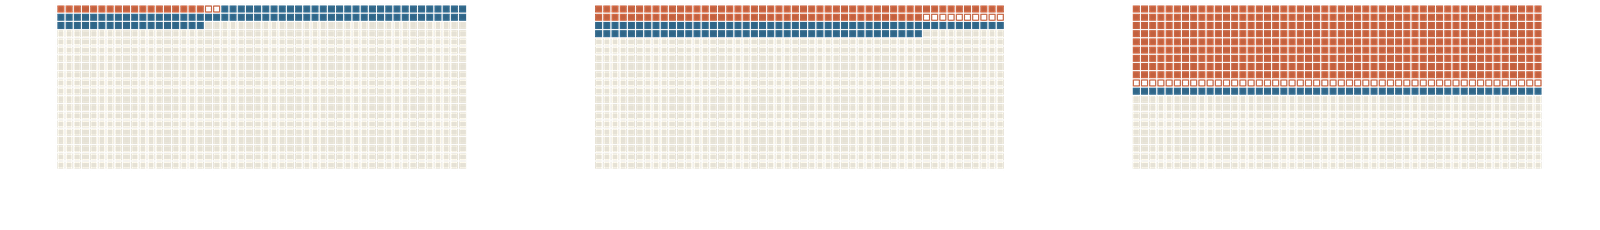

## Kỳ vọng và log-loss: trước khi biết đáp án

Một biến Bernoulli $Y\in\{0,1\}$ có $P(Y=1)=q$ thì $\E[Y]=q$, vì $0(1-q)+1q=q$. Do $Y^2=Y$, phương sai là $\operatorname{Var}(Y)=q-q^2=q(1-q)$. Với $q=0.02$, hai số lần lượt là $0.02$ và $0.0196$. Kỳ vọng mô tả trung bình qua nhiều lần rút; một nhóm 50 bài cụ thể vẫn có thể có 0, 1 hay 3 bài lỗi.

Nếu model xuất xác suất $p$ của lớp 1 và nhãn thật là $y$, binary cross-entropy là

$$L(p,y)=-y\log p-(1-y)\log(1-p).$$

Ta dùng logarithm tự nhiên nên loss có đơn vị nats. Khi $y=1$, $p=0.8$ cho loss $-\log0.8\approx0.2231$; dự đoán tự tin sai $p=0.2$ cho khoảng $1.6094$. Accuracy không thấy mức tự tin này nếu hai xác suất vẫn ở cùng một phía threshold.

BCE chính là $-\log$ của xác suất mà model gán cho nhãn thật, tức negative log-likelihood của một mẫu Bernoulli. Vì $\log$ tăng ngặt, tham số làm likelihood của cả tập lớn nhất cũng làm tổng log-loss nhỏ nhất: maximum likelihood và tối thiểu log-loss là cùng một bài toán.

Trước khi biết $Y$, kỳ vọng loss của dự đoán cố định $p$ là $-q\log p-(1-q)\log(1-p)$. Giá trị nhỏ nhất đạt tại $p=q$ khi $0<q<1$; thay vào cho entropy $H(q)$. Nói cách khác, biết tỉ lệ lớp thật thì xác suất phản ánh tỉ lệ đó là dự đoán tối ưu cho log-loss, chưa chắc là quyết định tối ưu cho mọi chi phí hành động.

In [ ]:
def expected_log_loss(q, p):
    return -q * np.log(p) - (1 - q) * np.log(1 - p)

q = 0.02
print(f"E[Y]={q:.4f}, Var(Y)={q * (1 - q):.4f}")
print(f"y=1: loss tại p=0.8 là {-np.log(0.8):.4f}; tại p=0.2 là {-np.log(0.2):.4f}")
print(f"E[loss] tại p=0.02: {expected_log_loss(q, 0.02):.4f}")
print(f"E[loss] tại p=0.50: {expected_log_loss(q, 0.50):.4f}")
assert expected_log_loss(q, q) < expected_log_loss(q, 0.5)

E[Y]=0.0200, Var(Y)=0.0196
y=1: loss tại p=0.8 là 0.2231; tại p=0.2 là 1.6094
E[loss] tại p=0.02: 0.0980
E[loss] tại p=0.50: 0.6931


Không lấy `log(0)` trong code tính tay; nó cho vô cùng. Với logits, thư viện có loss gộp sigmoid hoặc softmax để tính ổn định hơn. Một vector xác suất phải không âm và tổng bằng 1; một vector logits không có hai điều kiện này. Khi trình bày, cần nói model đang xuất đại lượng nào.

**Hỏi nhanh.** Trong tập train, 30% nhãn là 1. Model chỉ được xuất **một** xác suất $p$ cho mọi mẫu. Giá trị $p$ nào cho log-loss trung bình nhỏ nhất?

- A. $p = 0$, vì đa số nhãn là 0
- B. $p = 0.3$, đúng bằng tỉ lệ nhãn 1
- C. $p = 0.5$, vì chưa biết gì về mẫu
- D. $p = 0.7$, đúng bằng tỉ lệ nhãn 0

<details><summary>Đáp án</summary>

B. $p = 0.3$, đúng bằng tỉ lệ nhãn 1

Log-loss trung bình là $-0.3\log p - 0.7\log(1 - p)$, nhỏ nhất tại $p = 0.3$, với giá trị $H(0.3) \approx 0.611$, thấp hơn $\log 2 \approx 0.693$ của $p = 0.5$. $p = 0$ cho loss vô cùng ở mọi mẫu nhãn 1. Đoán theo đa số có ích cho accuracy, nhưng không có ích cho log-loss. $0.7$ là tỉ lệ của lớp 0, đặt nhầm vào chỗ xác suất của lớp 1.

</details>



## Đại số tuyến tính: phép nhân mô tả việc gì?

Ta có hai mẫu, mỗi mẫu hai feature, xếp thành hàng của $X$. Linear model với $\mathbf w=(2,-1)$ và $b=1$ cho

$$X=\begin{bmatrix}1&2\\3&4\end{bmatrix},\qquad\hat{\mathbf y}=X\mathbf w+b=\begin{bmatrix}1\\3\end{bmatrix}.$$

Hàng đầu có $1\cdot2+2\cdot(-1)+1=1$; hàng sau có $3\cdot2+4\cdot(-1)+1=3$. Bias cộng vào mỗi mẫu. Shape của $X$ là `(2, 2)`, của $\mathbf w$ là `(2,)`, của kết quả là `(2,)`. Vector một chiều trong NumPy không tự thành cột hai chiều như cách vẽ trên giấy.

In [ ]:
X = np.array([[1.0, 2.0], [3.0, 4.0]])
w_linear = np.array([2.0, -1.0])
b_linear = 1.0
prediction = X @ w_linear + b_linear
print("Shape:", X.shape, w_linear.shape, prediction.shape)
print("Dự đoán:", prediction)
assert np.allclose(prediction, [1.0, 3.0])

dependent = np.array([[1.0, 2.0], [2.0, 4.0]])
null_direction = np.array([2.0, -1.0])
print("Hướng không thay đổi dự đoán:", dependent @ null_direction)
print("Hạng ma trận:", np.linalg.matrix_rank(dependent))

Shape: (2, 2) (2,) (2,)
Dự đoán: [1. 3.]
Hướng không thay đổi dự đoán: [0. 0.]
Hạng ma trận: 1


Ma trận `dependent` có cột thứ hai gấp đôi cột thứ nhất, nên hạng bằng 1. Thêm $t(2,-1)$ vào trọng số không đổi dự đoán, vì tích với hướng ấy bằng 0. Bởi vậy một nghiệm hệ số chưa chắc duy nhất; muốn dùng nghịch đảo hay nói “nghiệm duy nhất”, phải kiểm điều kiện hạng. Đây là lý do ở bài 2.1 ta cần least squares và regularization khi feature phụ thuộc.



Tích vô hướng $\mathbf u^\top\mathbf v$ vừa dùng để dự đoán, vừa đo quan hệ hình học. Với hai vector khác 0, cosine similarity chia tích vô hướng cho tích độ dài. Nó không đổi khi nhân một vector với số dương; khoảng cách Euclidean thường đổi. Vì vậy similarity và khoảng cách cần được chọn theo ý nghĩa của embedding, không chỉ theo công thức thuận tay. Vector 0 không có hướng nên cosine của nó không được định nghĩa bằng phép chia thông thường.

**Hỏi nhanh.** `X` có shape `(5, 3)`, `w` có shape `(3,)`, còn `b` là một số. `X @ w + b` có shape gì?

- A. `(3,)`
- B. `(5, 3)`
- C. `(5, 1)`
- D. `(5,)`

<details><summary>Đáp án</summary>

D. `(5,)`

Mỗi hàng cho một tích vô hướng, nên có năm dự đoán, và số `b` được cộng vào từng phần tử. NumPy giữ kết quả là một chiều `(5,)`, không tự thành cột `(5, 1)`. `(3,)` là shape của `w`. `(5, 3)` là kết quả của `X * w`, phép nhân từng phần tử có broadcast.

</details>

## Gradient: chia sai số về đúng tham số

Giờ dùng một mẫu phân loại: $\mathbf x=(1,2)$, nhãn $y=1$, trọng số $\mathbf w=(0.2,-0.1)$, bias $b=0$. Logit $z=\mathbf w^\top\mathbf x+b=0$, xác suất $p=\sigma(z)=0.5$. Loss là $\log2\approx0.6931$.



Chain rule nói đạo hàm qua nhiều phép tính là tích các đạo hàm cục bộ. Với binary cross-entropy và sigmoid ghép đúng, các số hạng rút gọn thành

$$\frac{\partial L}{\partial z}=p-y,\qquad\nabla_{\mathbf w}L=(p-y)\mathbf x,\qquad\frac{\partial L}{\partial b}=p-y.$$

Vậy gradient của $\mathbf w$ là $(-0.5,-1)$, của $b$ là $-0.5$. Gradient descent với $\eta=0.1$ cho $\mathbf w'=(0.25,0)$, $b'=0.05$. Logit mới bằng $0.3$, xác suất tăng lên khoảng $0.5744$, loss giảm còn khoảng $0.5544$. Nhãn là 1 nên dấu thay đổi có nghĩa: model cần tăng xác suất lớp 1.

Ta gộp $\boldsymbol\theta=(w_1,w_2,b)$ để kiểm cả ba thành phần bằng sai phân trung tâm. `logaddexp(0, z)` tính $\log(1+e^z)$ ổn định; loss từ logit là biểu thức đó trừ $yz$.

In [ ]:
x = np.array([1.0, 2.0])
y = 1.0
theta = np.array([0.2, -0.1, 0.0])

def logistic_loss(parameters):
    z = x @ parameters[:2] + parameters[2]
    return float(np.logaddexp(0.0, z) - y * z)

def logistic_gradient(parameters):
    z = x @ parameters[:2] + parameters[2]
    p = 1.0 / (1.0 + np.exp(-z))
    return np.append((p - y) * x, p - y)

gradient = logistic_gradient(theta)
h = 1e-5
numerical = np.zeros_like(theta)
for j in range(len(theta)):
    shift = np.zeros_like(theta)
    shift[j] = h
    numerical[j] = (logistic_loss(theta + shift) - logistic_loss(theta - shift)) / (2 * h)
new_theta = theta - 0.1 * gradient
print("Gradient:", gradient)
print("Tham số mới:", new_theta)
print(f"Loss: {logistic_loss(theta):.4f} -> {logistic_loss(new_theta):.4f}")
print("Sai phân khớp:", np.allclose(gradient, numerical, atol=1e-8))
assert np.allclose(gradient, [-0.5, -1.0, -0.5])
assert logistic_loss(new_theta) < logistic_loss(theta)

Gradient: [-0.5 -1.  -0.5]
Tham số mới: [0.25 0.   0.05]
Loss: 0.6931 -> 0.5544
Sai phân khớp: True


Gradient cho xấp xỉ bậc nhất $L(\boldsymbol\theta+\boldsymbol\Delta)\approx L(\boldsymbol\theta)+\nabla L^\top\boldsymbol\Delta$ khi $\boldsymbol\Delta$ nhỏ. Đạo hàm âm theo một tham số nghĩa là tăng tham số ấy một chút thì loss giảm, nên bước descent $\boldsymbol\Delta=-\eta\nabla L$ làm nó tăng. Tình huống loss tăng ở đầu bài thường có một trong hai nguyên nhân: cộng gradient thay vì trừ, hoặc bước quá lớn, vượt khỏi vùng mà xấp xỉ tuyến tính còn dùng được.

**Hỏi nhanh.** Tại $w_1 = 3$, đạo hàm $\partial L/\partial w_1 = -2$. Tăng $w_1$ lên $3.001$, giữ nguyên các tham số khác. Loss thay đổi xấp xỉ bao nhiêu?

- A. Giảm khoảng $0.002$
- B. Tăng khoảng $0.002$
- C. Giảm khoảng $2$
- D. Không đổi, vì bước quá nhỏ

<details><summary>Đáp án</summary>

A. Giảm khoảng $0.002$

$\Delta L \approx (-2)(0.001) = -0.002$. Đạo hàm âm nghĩa là tăng tham số thì loss giảm, chứ không tăng. 2 là quên nhân với độ dịch $0.001$. Bước nhỏ thì thay đổi nhỏ, chứ không bằng 0. Chính vì bước nhỏ mà xấp xỉ bậc nhất mới đáng tin.

</details>

Gradient bằng 0 là điểm dừng, không tự chứng minh đó là cực tiểu toàn cục của một mạng phi tuyến. Với loss lồi, như MSE của linear regression hay log-loss của logistic regression, mọi điểm dừng đều là cực tiểu toàn cục; cần nói rõ lớp hàm đang xét.

Nếu thêm penalty $\lambda\lVert\mathbf w\rVert^2$ thì gradient theo $\mathbf w$ có thêm $2\lambda\mathbf w$. Nếu đề dùng $\lambda\lVert\mathbf w\rVert^2/2$, số 2 biến mất. Trên một batch, loss lấy trung bình cũng làm gradient có hệ số $1/n$. Viết rõ loss trước khi đạo hàm là cách tránh chép nhầm quy ước.

**Hỏi nhanh.** Gradient theo bias là $-0.6$, learning rate là $0.2$, và bias ban đầu là $1$. Sau một bước gradient descent, bias mới bằng bao nhiêu?

- A. $-0.12$
- B. $0.88$
- C. $1.12$
- D. $1.6$

<details><summary>Đáp án</summary>

C. $1.12$

$b' = 1 - 0.2\cdot(-0.6) = 1.12$. $0.88$ là cộng gradient thay vì trừ, tức đi ngược hướng giảm loss. $-0.12$ chỉ lấy $\eta g$ mà quên giá trị cũ. $1.6$ là trừ gradient nhưng quên nhân learning rate. Descent không phải lúc nào cũng làm tham số nhỏ đi: gradient âm thì tham số tăng.

</details>

## Kiến trúc mạng: đếm shape trước khi đếm tham số

Một câu lý thuyết về CNN thường chỉ cần phân biệt số mẫu, channel và không gian. Với convolution không dilation, input cao $H$, kernel $k$, padding $p$, stride $s$, chiều cao đầu ra là

$$H_{\text{out}}=\left\lfloor\frac{H+2p-k}{s}\right\rfloor+1.$$

Input `(N, C, H, W) = (4, 3, 8, 8)`, hai output channel, $k=3$, $p=1$, $s=2$ cho $H_{\text{out}}=W_{\text{out}}=4$. Shape output là `(4, 2, 4, 4)`. Mỗi output channel dùng $3\cdot3\cdot3=27$ weight và một bias, tổng $2(27+1)=56$ tham số. Tổng quát, `Conv2d` có $C_{\text{out}}(C_{\text{in}}k^2+1)$ tham số, bỏ số 1 khi `bias=False`; cách đặt này thường gặp khi BatchNorm đứng ngay sau, vì BatchNorm đã có tham số dịch riêng. Batch size và số vị trí ảnh không nhân vào số tham số: các weight được dùng lại ở nhiều vị trí.



In [ ]:
import torch

torch.manual_seed(0)
conv = torch.nn.Conv2d(3, 2, kernel_size=3, stride=2, padding=1)
images = torch.zeros(4, 3, 8, 8)
with torch.no_grad():
    conv_output = conv(images)
parameter_count = sum(parameter.numel() for parameter in conv.parameters())
print("Output shape:", tuple(conv_output.shape))
print("Số tham số:", parameter_count)
assert tuple(conv_output.shape) == (4, 2, 4, 4)
assert parameter_count == 56

Output shape: (4, 2, 4, 4)
Số tham số: 56


Một forward trên tensor toàn 0 đủ để kiểm shape và số tham số; không cần train. Nếu đề có dilation $d$, thay $k$ bằng effective size $d(k-1)+1$. Kernel $1\times1$ vẫn có $C_{\text{in}}C_{\text{out}}$ weight: nó không nhìn lân cận nhưng trộn các channel tại từng vị trí. Pooling thường không có weight học được; residual addition yêu cầu shape hai nhánh khớp hoặc có projection để đưa về cùng shape.

**Hỏi nhanh.** Input `(8, 16, 32, 32)` đi qua `Conv2d(16, 32, kernel_size=3, padding=1)`, stride 1, có bias. Output có shape gì, và lớp có bao nhiêu tham số?

- A. `(8, 32, 30, 30)`, 4640 tham số
- B. `(8, 16, 32, 32)`, 4640 tham số
- C. `(8, 32, 32, 32)`, 4608 tham số
- D. `(8, 32, 32, 32)`, 4640 tham số

<details><summary>Đáp án</summary>

D. `(8, 32, 32, 32)`, 4640 tham số

$H_{\text{out}} = \lfloor(32 + 2 - 3)/1\rfloor + 1 = 32$, và số channel ra là 32. Mỗi output channel có $16\cdot 3\cdot 3 = 144$ weight và 1 bias, tổng cộng $32\cdot 145 = 4640$. 4608 là quên bias. 30 là quên padding. Giữ 16 channel là nhầm số channel vào với số channel ra.

</details>

## Attention: một hàng là một cách lấy trung bình

Với một head, $Q$ có shape `(Tq, dk)`, $K$ có shape `(Tk, dk)`, $V$ có shape `(Tk, dv)`. Ma trận score $QK^\top/\sqrt{d_k}$ có shape `(Tq, Tk)`. Softmax theo trục key tạo một phân phối cho **mỗi query**, rồi nhân $V$ để lấy tổng có trọng số:

$$O=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V.$$

Ta chọn $Q=K=I_2$, tức ma trận đơn vị 2 chiều, và hai value là $(2,0)$, $(0,4)$. Score của query đầu là $(1/\sqrt2,0)$. Softmax cho trọng số khoảng $(0.6698,0.3302)$, nên output đầu là $(1.3395,1.3210)$. Đây là vector giá trị pha trộn, không phải index của một token được chọn.



In [ ]:
Q = np.eye(2)
K = np.eye(2)
values = np.array([[2.0, 0.0], [0.0, 4.0]])

def row_softmax(scores):
    shifted = scores - scores.max(axis=1, keepdims=True)
    exponentials = np.exp(shifted)
    return exponentials / exponentials.sum(axis=1, keepdims=True)

scores = Q @ K.T / np.sqrt(Q.shape[1])
weights = row_softmax(scores)
attention_output = weights @ values
print("Trọng số:\n", weights.round(4))
print("Output:\n", attention_output.round(4))
assert np.allclose(weights.sum(axis=1), 1.0)

masked_scores = scores.copy()
masked_scores[0, 1] = -np.inf       # query đầu không nhìn token tương lai
causal_weights = row_softmax(masked_scores)
print("Output đầu với causal mask:", (causal_weights @ values)[0])
assert np.allclose(causal_weights[0], [1.0, 0.0])

Trọng số:
 [[0.6698 0.3302]
 [0.3302 0.6698]]
Output:
 [[1.3395 1.321 ]
 [0.6605 2.679 ]]
Output đầu với causal mask: [2. 0.]


Đặt mask vào score **trước** softmax làm xác suất bị cấm bằng 0 rồi chuẩn hóa lại phần được phép. Đặt một weight về 0 sau softmax mà không chuẩn hóa lại làm tổng hàng nhỏ hơn 1. Nếu một query bị mask toàn bộ key, softmax không có phân phối hợp lệ; cần xử lý theo thiết kế của model, không mong phép tính tự hiểu padding.

Trong một layer thật, $Q=XW_Q$, $K=XW_K$, $V=XW_V$ với $X$ shape `(T, d_model)`, rồi các head được nối lại và đi qua một phép chiếu ra. Tham số nằm ở các ma trận chiếu, nên số tham số không phụ thuộc độ dài chuỗi $T$; ngược lại, ma trận score `(T, T)` tăng theo $T^2$. Đếm tham số và đếm bộ nhớ là hai câu hỏi khác nhau.

**Hỏi nhanh.** `Q` có shape `(3, 2)`, `K` có shape `(5, 2)`, `V` có shape `(5, 4)`. Output của một head có shape gì?

- A. `(5, 4)`
- B. `(3, 5)`
- C. `(3, 4)`
- D. `(2, 4)`

<details><summary>Đáp án</summary>

C. `(3, 4)`

Score và weight có shape `(3, 5)`, nhân với `(5, 4)` thì được `(3, 4)`, tức một vector output cho mỗi query. `(3, 5)` mới chỉ là trọng số, chưa nhân với value. `(5, 4)` là shape của `V`. `(2, 4)` là lấy nhầm $d_k$ làm số hàng.

</details>

**Hỏi nhanh.** Query thứ hai chỉ được nhìn key 1 và key 2. Score cho ba key là $(0, \log 3, \log 2)$, với log tự nhiên. Đặt score của key 3 thành $-\infty$ trước khi softmax. Bộ trọng số thu được là gì?

- A. $(1/6, 3/6, 2/6)$
- B. $(1/4, 3/4, 0)$
- C. $(1/6, 3/6, 0)$
- D. $(0, 1, 0)$

<details><summary>Đáp án</summary>

B. $(1/4, 3/4, 0)$

Sau mask, các exponential là $(1, 3, 0)$. Chuẩn hóa trên tổng 4 thì được $(1/4, 3/4, 0)$. $(1/6, 3/6, 2/6)$ là softmax khi quên mask. $(1/6, 3/6, 0)$ là cắt xác suất sau softmax mà không chuẩn hóa lại, nên tổng chỉ còn $4/6$. $(0, 1, 0)$ là argmax, không phải softmax.

</details>

## Đánh giá: trở lại detector đầu bài

Bảng 1000 bài có $TP=18$, $FN=2$, $FP=98$, $TN=882$. Recall bằng $TP/(TP+FN)=0.9$, trả lời “bắt được bao nhiêu bài lỗi?”. Precision bằng $TP/(TP+FP)=18/116\approx0.1552$, trả lời “cảnh báo đáng tin tới đâu?”. Hai số đúng là hai xác suất có điều kiện đã gặp ở đầu bài.

Accuracy bằng $(TP+TN)/1000=0.9$. Nhưng baseline luôn đoán sạch có accuracy $0.98$ và recall 0. Không thể từ một số 0.98 kết luận baseline giải quyết mục tiêu tìm lỗi tốt hơn; cũng không thể bỏ qua 98 cảnh báo nhầm vì recall cao. Metric cần phản ánh yêu cầu và chi phí kiểm thủ công của bài.

F1 dùng trung bình điều hòa của precision và recall, tương đương

$$F1=\frac{2TP}{2TP+FP+FN}=\frac{36}{136}\approx0.2647.$$

Để đối chiếu với scikit-learn, ta dựng lại vector nhãn và vector dự đoán đúng theo bốn ô của bảng.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

labels = np.array([1] * (tp + fn) + [0] * (fp + tn))
predicted = np.array([1] * tp + [0] * fn + [1] * fp + [0] * tn)
accuracy = (tp + tn) / total
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * tp / (2 * tp + fp + fn)
library = np.array([
    accuracy_score(labels, predicted), precision_score(labels, predicted),
    recall_score(labels, predicted), f1_score(labels, predicted),
])
assert np.allclose(library, [accuracy, precision, recall, f1])
print(f"Accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, F1={f1:.4f}")
print(f"Baseline sạch: accuracy={(fp + tn) / total:.4f}, recall=0.0000")
print("Tính tay khớp thư viện:", True)

Accuracy=0.9000, precision=0.1552, recall=0.9000, F1=0.2647
Baseline sạch: accuracy=0.9800, recall=0.0000
Tính tay khớp thư viện: True




Khi chấm model thật, chỉ dùng train để fit tham số; chọn threshold, kiến trúc và hyperparameter bằng validation phù hợp, rồi giữ test để đánh giá cuối. Với nhiều bài của cùng một người hoặc cùng một nguồn, random split có thể lọt kiểu viết giữa train và validation; lúc ấy cần group split. Nếu mục tiêu dự đoán ở tương lai, cách chia theo thời gian có thể phù hợp hơn. Stratification giữ tỉ lệ lớp nhưng không tự chữa leakage theo nhóm.

**Hỏi nhanh.** Mỗi học sinh nộp nhiều bài, và bài của cùng một người có mặt ở cả train lẫn validation. Mục tiêu là dự đoán cho học sinh mới. Stratification theo nhãn có xử lý được rủi ro này không?

- A. Không, cần chia theo người, tức group split
- B. Có, vì tỉ lệ nhãn ở hai phần đã bằng nhau
- C. Có, nếu model đủ nhỏ để không nhớ được từng người
- D. Không, cần chia theo thời gian nộp bài

<details><summary>Đáp án</summary>

A. Không, cần chia theo người, tức group split

Stratification chỉ giữ tỉ lệ nhãn, không ngăn kiểu viết của một người xuất hiện ở cả hai phía. Validation khi đó đo khả năng nhận ra người cũ, nên lạc quan so với học sinh mới. Model nhỏ vẫn học được những dấu hiệu ấy. Chia theo thời gian hợp với mục tiêu dự đoán tương lai, nhưng vẫn có thể để một người ở cả hai phía.

</details>

Một điểm trên tập nhỏ có sai số lấy mẫu. Nếu 1000 kết quả đúng hay sai thật sự độc lập và cùng xác suất đúng 0.9, độ lệch chuẩn của accuracy mẫu là $\sqrt{0.9\cdot0.1/1000}\approx0.0095$. Giả thiết độc lập là phần quan trọng: nếu nhiều mẫu đến từ cùng một người, chúng tương quan và độ bất định thật lớn hơn con số này. Hai model nên được so trên cùng split và đọc loại lỗi của chúng, không chỉ xếp hạng một điểm duy nhất.

**Hỏi nhanh.** Với 1000 mẫu độc lập và accuracy thật là 0.9, độ lệch chuẩn của accuracy đo được khoảng $0.0095$. Nếu validation chỉ có 100 mẫu thì khoảng bao nhiêu?

- A. $0.00095$
- B. $0.0095$
- C. $0.03$
- D. $0.095$

<details><summary>Đáp án</summary>

C. $0.03$

$\sqrt{0.9\cdot 0.1/100} = 0.03$. Giảm số mẫu đi 10 lần làm độ lệch chuẩn tăng $\sqrt{10} \approx 3.16$ lần, chứ không phải 10 lần. Trên 100 mẫu, hai model chênh nhau một hai điểm phần trăm thì chưa đủ để xếp hạng. $0.095$ là nhân 10. $0.00095$ là chia 10. $0.0095$ là quên rằng độ lệch chuẩn phụ thuộc số mẫu.

</details>



## Khi đi thi

- **Viết đại lượng cần tìm trước khi thế số.** Ghi rõ điều kiện ($P(B\mid F)$ hay $P(F\mid B)$), giả thiết độc lập và đơn vị; vẽ bảng bốn ô hoặc bảng shape khi dễ nhầm.
- **Đạo hàm từ một loss viết đầy đủ.** Ghi hệ số $1/n$, $\lambda$ hay $\lambda/2$, bias có bị phạt không; dùng chain rule, rồi kiểm dấu trên một mẫu, hoặc bằng sai phân trung tâm nếu được chạy code.
- **Kiến trúc: shape trước, tham số sau.** Tính shape từng lớp, rồi đếm $C_{\text{out}}(C_{\text{in}}k^2+1)$ cho conv và các ma trận chiếu cho attention; batch và độ dài chuỗi không nhân vào số tham số.
- **Metric: ghi positive class, threshold, averaging.** Đặt baseline đoán đa số cạnh mọi accuracy trên dữ liệu lệch lớp, và nhớ rằng precision đổi theo tỉ lệ lớp.
- **Chạy code không thay chứng minh.** Vài lần chạy chỉ là kiểm tra cho khẳng định “với mọi”; một phản ví dụ nhỏ thì đủ để bác bỏ.
- **Đọc syllabus trước khi phân thời gian luyện.** Tỉ lệ câu viết, câu tính và câu code khác nhau giữa các kỳ thi.

## Tóm tắt

- Điều kiện xác suất quyết định mẫu số; Bayes, confusion matrix và precision có thể mô tả cùng một câu hỏi.
- Log-loss là negative log-likelihood; xác suất khớp tỉ lệ thật cho log-loss kỳ vọng nhỏ nhất.
- Đại số tuyến tính mô tả phép gộp feature, shape và tính duy nhất của nghiệm. Không nghịch đảo khi chưa kiểm điều kiện.
- Gradient đi qua từng phép tính; loss, dấu và phép lấy trung bình phải nhất quán với code.
- Convolution dùng lại tham số; attention chuẩn hóa theo key cho mỗi query. Shape giúp kiểm cả hai.
- Metric trả lời một mục tiêu cụ thể. Một điểm validation chỉ có ý nghĩa cùng cách chia, baseline và phạm vi dữ liệu.

## Kiểm tra cuối bài

**Câu 1.** Trong 1000 bài nộp, có 200 bài dùng đệ quy, gọi là biến cố $A$, 100 bài bị quá thời gian, gọi là biến cố $T$, và 40 bài vừa dùng đệ quy vừa quá thời gian. $A$ và $T$ có độc lập không?

- A. Có, vì 40 bài chỉ là một phần nhỏ của 1000 bài
- B. Có, vì 40 nhỏ hơn cả 100 lẫn 200
- C. Chưa kết luận được khi chưa biết quan hệ nhân quả
- D. Không, vì $P(T\mid A) = 0.2$ khác với $P(T) = 0.1$

<details><summary>Đáp án</summary>

D. Không, vì $P(T\mid A) = 0.2$ khác với $P(T) = 0.1$

Độc lập nghĩa là $P(A\cap T) = P(A)P(T)$. Ở đây $P(A)P(T) = 0.2\cdot 0.1 = 0.02$, tức khoảng 20 bài nếu độc lập, nhưng thực tế có 40 bài. Nói cách khác, $P(T\mid A) = 40/200 = 0.2$, gấp đôi $P(T)$. Một tỉ lệ nhỏ, hay “nhỏ hơn”, không nói gì về độc lập. Kiểm độc lập chỉ cần các xác suất, còn nhân quả là một câu hỏi khác. Sự phụ thuộc này cũng không chứng minh đệ quy gây ra quá thời gian.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 62](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=25)

</details>

**Câu 2.** Hàm $f(\theta)$ có argmax duy nhất là $\theta^*$, và có thể nhận giá trị âm, như một log-likelihood. Hàm nào **không** chắc có cùng argmax $\theta^*$?

- A. $f(\theta) + 2$
- B. $3f(\theta)$
- C. $e^{f(\theta)}$
- D. $f(\theta)^2$

<details><summary>Đáp án</summary>

D. $f(\theta)^2$

Cộng một hằng số, nhân với một số dương, và lấy $e^{(\cdot)}$ đều là biến đổi tăng ngặt, nên giữ thứ tự và giữ argmax. Cũng vì $\log$ tăng ngặt mà cực đại likelihood tương đương với cực đại log-likelihood. Bình phương thì không tăng trên số âm. Với $f(\theta) = -(\theta - 1)^2 - 1$, argmax là $\theta = 1$, nhưng $f^2 = ((\theta - 1)^2 + 1)^2$ lại nhỏ nhất tại đó. Log-likelihood thường âm, nên bình phương nó là một lỗi có thật.
Phỏng theo: [CMU 10-601 · Exam 1 Practice · Q5.1](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=19)

</details>

**Câu 3.** Hai model có cùng accuracy 95% trên một tập nhị phân. Model A luôn báo xác suất 0.999 cho lớp nó chọn, còn model B luôn báo 0.95. Log-loss trung bình, với log tự nhiên, của hai model là bao nhiêu?

- A. A khoảng 0.001, B khoảng 0.05
- B. A khoảng 0.35, B khoảng 0.20
- C. A khoảng 0.20, B khoảng 0.35
- D. Bằng nhau, vì cùng accuracy

<details><summary>Đáp án</summary>

B. A khoảng 0.35, B khoảng 0.20

A được $0.95(-\log 0.999) + 0.05(-\log 0.001) \approx 0.001 + 0.345 = 0.346$. B được $0.95(-\log 0.95) + 0.05(-\log 0.05) \approx 0.049 + 0.150 = 0.199$. Mỗi mẫu sai của A bị phạt $\log 1000 \approx 6.9$. Cặp 0.001 và 0.05 là chỉ tính các mẫu đúng. Accuracy chỉ nhìn mẫu nằm phía nào của threshold, nên không phân biệt được hai model. Log-loss thưởng cho xác suất khớp với tần suất đúng, như kết luận $p = q$ của bài.

</details>

**Câu 4.** Linear regression với MSE, và ma trận dữ liệu có cột thứ hai gấp đôi cột thứ nhất. Kết luận nào đúng?

- A. Không có cực tiểu toàn cục, vì $X^\top X$ không khả nghịch
- B. Có đúng một cực tiểu toàn cục, vì MSE là hàm lồi
- C. Có vô số cực tiểu toàn cục, cùng cho một dự đoán trên train
- D. GD có thể kẹt ở một cực tiểu địa phương kém hơn

<details><summary>Đáp án</summary>

C. Có vô số cực tiểu toàn cục, cùng cho một dự đoán trên train

MSE là hàm bậc hai lồi theo $\mathbf w$, và phương trình $X^\top X\mathbf w = X^\top\mathbf y$ luôn có nghiệm, vì $X\mathbf w$ là hình chiếu của $\mathbf y$ lên không gian cột. Vì vậy cực tiểu toàn cục luôn tồn tại, và mọi cực tiểu địa phương đều là toàn cục. Nhưng hàm không lồi chặt: thêm $t(2, -1)$ vào $\mathbf w$ không làm đổi $X\mathbf w$, nên cả một đường thẳng nghiệm có cùng loss và cùng dự đoán. $X^\top X$ suy biến chỉ làm công thức nghịch đảo không dùng được, chứ không làm mất nghiệm. GD với bước đủ nhỏ hội tụ về một nghiệm trong số đó, tùy điểm khởi đầu.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q1.2](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=4)

</details>

**Câu 5.** Logistic regression trên ba điểm: $(1, 1)$ nhãn 0, $(1, 0)$ nhãn 1, $(0, 0)$ nhãn 0. Model 1 là $\sigma(w_1x_1 + w_2x_2)$, còn model 2 có thêm bias $w_0$. Đổi nhãn của $(0, 0)$ thành 1, rồi chạy GD từ cùng khởi tạo, với cùng learning rate. Chuyện gì xảy ra?

- A. Model 1 đi đúng quỹ đạo cũ, còn model 2 đi khác
- B. Model 1 đi khác, còn model 2 đi đúng quỹ đạo cũ
- C. Cả hai model đều đi đúng quỹ đạo cũ
- D. Cả hai model đều đi khác, vì dữ liệu đã đổi

<details><summary>Đáp án</summary>

A. Model 1 đi đúng quỹ đạo cũ, còn model 2 đi khác

Đóng góp của một mẫu vào gradient theo weight là $(p - y)\mathbf x$, bằng 0 khi $\mathbf x = \mathbf 0$, dù nhãn là gì. Model 1 không có tham số nào khác, nên mọi bước GD giữ nguyên. Model 2 có $\partial L/\partial w_0 = \sum_i(p_i - y_i)$. Đổi $y$ từ 0 sang 1 làm số hạng này giảm 1 ngay từ bước đầu, nên bias đi khác, rồi kéo theo cả weight. Không có bias, model 1 luôn cho $p = 0.5$ tại gốc tọa độ, nên nó không thể học được nhãn của điểm ấy.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q2.2](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=6)

</details>

**Câu 6.** Logistic regression viết mục tiêu dạng tổng như scikit-learn: $J(\mathbf w) = \sum_{i=1}^m\ell_i + \frac\lambda2\lVert\mathbf w_{1:}\rVert^2$, trong đó bias `w[0]` không bị phạt. Code tối ưu $J/m$, và đã có `g = X.T @ (p - y) / m`. Dòng nào cộng phần phạt vào cho đúng?

- A. `g += lam * w`
- B. `g[1:] += lam * w[1:]`
- C. `g[1:] += (lam / m) * w[1:]`
- D. `g += (lam / m) * w`

<details><summary>Đáp án</summary>

C. `g[1:] += (lam / m) * w[1:]`

Chia $J$ cho $m$ thì phần phạt thành $\frac{\lambda}{2m}\lVert\mathbf w_{1:}\rVert^2$, với đạo hàm $\frac{\lambda}{m}\mathbf w_{1:}$, chỉ từ phần tử 1 trở đi. Thiếu `/ m` là phạt mạnh gấp $m$ lần so với mục tiêu đã chọn: code vẫn chạy, nhưng cho ra một model khác. Cộng vào cả `g[0]` là phạt luôn bias, kéo xác suất nền về 0.5 dù dữ liệu lệch lớp. Trong scikit-learn, tham số `C` đóng vai $1/\lambda$.
Phỏng theo: [NOAI 2026 Singapore · Chung kết · Câu 5](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=7)

</details>

**Câu 7.** Đội dự đoán số khán giả $g = \boldsymbol\theta^\top\mathbf x$, và chịu chi phí $L = \alpha g + \beta\max(0, y - g)$: thuê $g$ ghế với giá $\alpha$ mỗi ghế, và mất $\beta$ cho mỗi người phải từ chối. Với $\alpha = 1$, $\beta = 4$, $\mathbf x = (1, 3)$, $y = 20$, và hiện tại $g = 12$, gradient $\nabla_{\boldsymbol\theta}L$ là gì?

- A. $(1, 3)$
- B. $(-3, -9)$
- C. $(-4, -12)$
- D. $(5, 15)$

<details><summary>Đáp án</summary>

B. $(-3, -9)$

Vì $y > g$, nhánh $\max$ đang hoạt động, nên $\partial L/\partial g = \alpha - \beta = -3$. Nhân với $\partial g/\partial\boldsymbol\theta = \mathbf x$ thì được $(-3, -9)$. GD trừ gradient, nên tăng $g$, vì thiếu ghế đắt hơn thừa ghế. $(1, 3)$ là gradient khi $y < g$, chỉ còn chi phí thuê. $(-4, -12)$ là quên số hạng $\alpha g$. $(5, 15)$ là sai dấu đạo hàm của $\max(0, y - g)$ theo $g$.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q5(d)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=14)

</details>

**Câu 8.** Một bottleneck block của ResNet-50, trong `layer3`, có ba convolution không bias, mỗi cái theo sau bởi BatchNorm: $1\times 1$ từ 1024 xuống 256 channel, $3\times 3$ từ 256 sang 256, và $1\times 1$ từ 256 lên 1024. Ba convolution này có tổng cộng bao nhiêu tham số?

- A. $1\,114\,112$
- B. $1\,115\,648$
- C. $589\,824$
- D. $5\,308\,416$

<details><summary>Đáp án</summary>

A. $1\,114\,112$

$1024\cdot 256 + 256\cdot 256\cdot 9 + 256\cdot 1024 = 262\,144 + 589\,824 + 262\,144 = 1\,114\,112$. Hai conv $1\times 1$ chiếm gần một nửa, dù kernel nhỏ nhất, vì chúng nối với 1024 channel. Chỉ đếm conv giữa thì được 589 824. Cộng thêm 1536 bias là quên `bias=False`. Tính hai conv $1\times 1$ như $3\times 3$ thì được 5 308 416.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 8.3](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=20)

</details>

**Câu 9.** Một layer multi-head attention có $d_{\text{model}} = 64$, $H = 4$ head, mỗi head có $d = 16$. Ba phép chiếu $Q$, $K$, $V$ đi từ $d_{\text{model}}$ lên $Hd$, phép chiếu ra đi từ $Hd$ về $d_{\text{model}}$, tất cả đều không bias. Thêm relative positional encoding: mỗi head học một vector $\mathbf r_{j-i} \in \mathbb R^{d}$ cho mỗi độ lệch $j - i$, với chuỗi dài $T = 10$. Tổng số tham số là bao nhiêu?

- A. $13\,504$
- B. $16\,688$
- C. $17\,024$
- D. $17\,600$

<details><summary>Đáp án</summary>

D. $17\,600$

Bốn ma trận chiếu có $4\cdot 64\cdot 64 = 16\,384$ tham số. Độ lệch $j - i$ chạy từ $-9$ đến $9$, tức $2T - 1 = 19$ giá trị, nên phần vị trí có $4\cdot 19\cdot 16 = 1216$ tham số, và tổng là $17\,600$. 13 504 là quên phép chiếu ra. 17 024 là chỉ đếm $T$ độ lệch. 16 688 là cho các head dùng chung $\mathbf r$. Chỉ có phần vị trí phụ thuộc $T$, và không phần nào phụ thuộc batch.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Part 1.3.1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=7)

</details>

**Câu 10.** Detector A có precision 0.5 và recall 0.5. Detector B có precision 0.9 và recall 0.1. Trung bình cộng hai chỉ số của cả hai đều bằng 0.5. F1 của mỗi detector bằng bao nhiêu?

- A. A được 0.50, B được 0.50
- B. A được 0.50, B được 0.18
- C. A được 0.25, B được 0.09
- D. A được 0.50, B được 0.90

<details><summary>Đáp án</summary>

B. A được 0.50, B được 0.18

F1 là trung bình điều hòa $2PR/(P + R)$. A được $2\cdot 0.25/1 = 0.5$. B được $2\cdot 0.09/1 = 0.18$. Trung bình điều hòa bị kéo về phía số nhỏ hơn, nên một detector chỉ bắt được 10% bài lỗi thì precision cao cũng không cứu được. 0.50 cho B là trung bình cộng. 0.25 và 0.09 là tích $PR$, quên hệ số $2/(P + R)$. 0.90 là lấy chỉ số lớn hơn.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 68](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=27)

</details>

## Đọc thêm

- Deisenroth, Faisal, Ong — [*Mathematics for Machine Learning*](https://mml-book.com/), chương 2, 5, 6 và 7. Đọc để nối đại số tuyến tính, đạo hàm nhiều biến, xác suất và tối ưu trong một hệ ký hiệu.
- Boyd, Vandenberghe — [*Introduction to Applied Linear Algebra*](https://web.stanford.edu/~boyd/vmls/). Dùng các ví dụ vector, hạng và least squares để luyện giải thích một phép nhân ma trận bằng lời.
- James và cộng sự — [*An Introduction to Statistical Learning with Applications in Python*](https://www.statlearning.com/), chương 2, 4 và 5. Đọc lỗi tổng quát hóa, xác suất phân loại và validation để đặt phép tính metric vào đúng quy trình.
- Ma, Ng — [*CS229 Lecture Notes*](https://cs229.stanford.edu/main_notes.pdf). Đọc các phần logistic regression và neural networks để đối chiếu chain rule với loss từ logits.
- Vaswani và cộng sự — [*Attention Is All You Need*, mục 3.2](https://arxiv.org/html/1706.03762v7). Đọc công thức scaled dot-product attention và lý do mask trước softmax.
- [PyTorch — Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) và [scikit-learn — Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html). Dùng để kiểm quy ước shape, bias, positive class và averaging của thư viện.